# Study 09 · 03 · E2 · Weather timing (look-ahead) and placebos

**Question.** Was the earlier −1.14% four-week "gain" (historical alignment, six seasons) caused by look-ahead, or by losing the most recent week of weather?

All arms share case history + geography and the fixed hyperparameters; only the weather window changes:

| Arm | Weather window | Publication rule |
|---|---|---|
| `b3_hist_geo` (lag 0) | 5-week means including the origin week | accepted up to origin + 14 days (**look-ahead**; notebook 00 confirmed it) |
| `b3_lag1` | ERA5-Land ending 1 week before the origin; CHIRPS 2 weeks before | everything published by the origin close |
| `b3_obs` (lag 2) | everything ending 2 weeks before the origin | everything published by the origin close |

Placebos (all at lag 2): temperature from the same district and epi-week of a donor year 1–4 years earlier, under three donor calendars (`b3_placebo_t1–t3`). In `b3_placebo_conjunto`, all four climate variables move together.

Each arm is compared with `historia_geo` (negative change = climate helps), over 18 seasons and over the paper's six.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

FIG = STUDY / "figures"
RES = c.OUTPUT / "resultados"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
base = pd.read_csv(c.OUTPUT / "baselines.csv.gz", dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])
hg = ex.sse(c.read_arm("historia_geo", columns=ex.PRED_COLUMNS))
lag_arms = {"lag 0 (historical, look-ahead)": "b3_hist_geo", "lag 1 (issue time)": "b3_lag1", "lag 2 (issue time, paper)": "b3_obs"}
placebos = ["b3_placebo_t1", "b3_placebo_t2", "b3_placebo_t3", "b3_placebo_conjunto"]
sse_by_arm = {arm: ex.sse(c.read_arm(arm, columns=ex.PRED_COLUMNS)) for arm in [*lag_arms.values(), *placebos]}
six_hg = ex.sse(c.read_arm("historia_geo", columns=ex.PRED_COLUMNS), seasons=c.DECISION_SEASONS)
six = {arm: ex.sse(c.read_arm(arm, columns=ex.PRED_COLUMNS), seasons=c.DECISION_SEASONS) for arm in lag_arms.values()}

## 1 · Brier change vs history+geography, by weather lag

In [2]:
rows = []
for label, arm in lag_arms.items():
    rows.append(ex.contrast(sse_by_arm[arm], hg).assign(arm=label, seasons="18 seasons"))
    rows.append(ex.contrast(six[arm], six_hg).assign(arm=label, seasons="6 decision seasons"))
lags = pd.concat(rows)[["arm", "seasons", "horizonte", "cambio_agrupado_%", "ic95_agrupado", "cambio_igual_peso_%", "ic95_igual_peso", "temporadas_a_mejor"]]
lags.to_csv(RES / "e2_rezagos.csv", index=False)
lags.round(2)

,arm,seasons,horizonte,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,ic95_igual_peso,temporadas_a_mejor
0,"lag 0 (historical, look-ahead)",18 seasons,2,-1.01,"(-2.05, -0.11)",-1.77,"(-3.47, -0.24)",13
1,"lag 0 (historical, look-ahead)",18 seasons,3,-1.49,"(-2.99, -0.22)",-2.57,"(-5.11, -0.35)",12
2,"lag 0 (historical, look-ahead)",18 seasons,4,-1.73,"(-3.67, -0.22)",-2.50,"(-5.91, 0.92)",12
0,"lag 0 (historical, look-ahead)",6 decision seasons,2,-0.88,"(-2.03, -0.05)",-1.19,"(-2.28, -0.19)",5
1,"lag 0 (historical, look-ahead)",6 decision seasons,3,-0.76,"(-2.15, 0.51)",-1.15,"(-2.51, 0.2)",4
2,"lag 0 (historical, look-ahead)",6 decision seasons,4,-0.66,"(-1.79, 0.48)",-1.14,"(-2.55, 0.24)",4
0,lag 1 (issue time),18 seasons,2,-0.49,"(-1.48, 0.35)",-1.10,"(-2.6, 0.2)",11
1,lag 1 (issue time),18 seasons,3,-0.51,"(-2.05, 0.52)",-1.39,"(-3.66, 0.56)",10
2,lag 1 (issue time),18 seasons,4,-0.38,"(-2.52, 1.16)",-1.22,"(-4.29, 1.66)",8
0,lag 1 (issue time),6 decision seasons,2,-0.24,"(-0.86, 0.31)",-0.46,"(-1.5, 0.36)",3


## 2 · Placebos: observed weather vs wrong-year weather (lag 2, 18 seasons)

In [3]:
obs = sse_by_arm["b3_obs"]
plac = pd.concat([ex.contrast(obs, sse_by_arm[p]).assign(placebo=p) for p in placebos])
median_t = (plac[plac.placebo.str.contains("_t")].groupby("horizonte")[["cambio_agrupado_%", "cambio_igual_peso_%"]]
            .median().reset_index().assign(placebo="median of the 3 temperature placebos"))
placebo_table = pd.concat([plac, median_t])[["placebo", "horizonte", "cambio_agrupado_%", "ic95_agrupado", "cambio_igual_peso_%", "temporadas_a_mejor"]]
placebo_table.to_csv(RES / "e2_placebos.csv", index=False)
placebo_table.round(2)

,placebo,horizonte,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,b3_placebo_t1,2,0.04,"(-0.43, 0.4)",-0.06,8.0
1,b3_placebo_t1,3,0.15,"(-0.6, 0.7)",0.04,6.0
2,b3_placebo_t1,4,0.13,"(-0.71, 0.8)",0.09,6.0
0,b3_placebo_t2,2,-0.24,"(-0.74, 0.23)",-0.91,12.0
1,b3_placebo_t2,3,-0.20,"(-0.97, 0.57)",-1.22,11.0
2,b3_placebo_t2,4,-0.34,"(-1.35, 0.66)",-1.84,12.0
0,b3_placebo_t3,2,0.08,"(-0.47, 0.54)",-0.89,10.0
1,b3_placebo_t3,3,0.32,"(-0.44, 0.91)",-1.15,7.0
2,b3_placebo_t3,4,0.41,"(-0.64, 1.13)",-1.67,7.0
0,b3_placebo_conjunto,2,-0.50,"(-1.54, 0.26)",-1.12,10.0


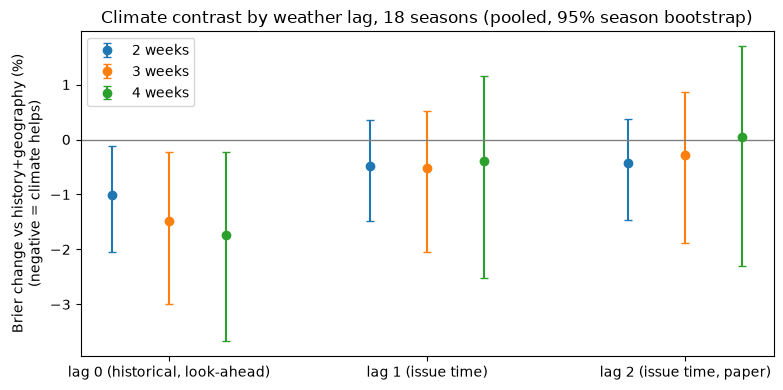

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = list(lag_arms)
for k, h in enumerate((2, 3, 4)):
    d = lags[(lags.seasons == "18 seasons") & lags.horizonte.eq(h)].set_index("arm").loc[labels]
    x = np.arange(len(labels)) + (k - 1) * 0.22
    lo = d["cambio_agrupado_%"] - d.ic95_agrupado.map(lambda t: t[0])
    hi = d.ic95_agrupado.map(lambda t: t[1]) - d["cambio_agrupado_%"]
    ax.errorbar(x, d["cambio_agrupado_%"], yerr=[lo, hi], fmt="o", capsize=3, label=f"{h} weeks")
ax.axhline(0, color="0.5", lw=1)
ax.set_xticks(range(len(labels)), labels)
ax.set_ylabel("Brier change vs history+geography (%)\n(negative = climate helps)")
ax.set_title("Climate contrast by weather lag, 18 seasons (pooled, 95% season bootstrap)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "e2_rezagos.png", dpi=160)